### SET UP


In [1]:
from evaluation import charts as ch

ch.use_static_copy()

---

# Long-term memory for an LLM assistant

An assistant that remembers its user has to keep facts across months of conversation, notice when they change, and bring up the right one at the right moment. The common answer is **vector memory**: store every message, and put the few most similar ones in front of the model.

This project built and tested a memory that does more: it extracts facts, tracks how they change, and decides what reaches the prompt. The data comes from 15 scripted test sets and 53 evaluation runs ([`../results/`](../results/README.md)), all answered by the same local model (llama3.1:8b).

| Mode | What reaches the model's prompt |
|---|---|
| **baseline** | vector search: the 4 past messages most similar to the question |
| **smart** | the first design: extracted facts and episode notes, instead of messages |
| **hybrid** | the final design: the baseline's 4 messages, outdated ones marked, plus current facts and a timeline for questions about the past |
| **full** | the whole history, as a reference |

---


## The first design on short histories

Vector memory cannot tell an old value from a new one, nor a past fact from a present one, and it does not know that an allergy matters when the question is about a recipe.

The first design, **smart**, replaces the messages with structured facts: the model extracts `lives_in = Milan` or `allergic_to = peanuts`, a new value supersedes the old one, and a relevance gate lets only matching facts into the prompt.


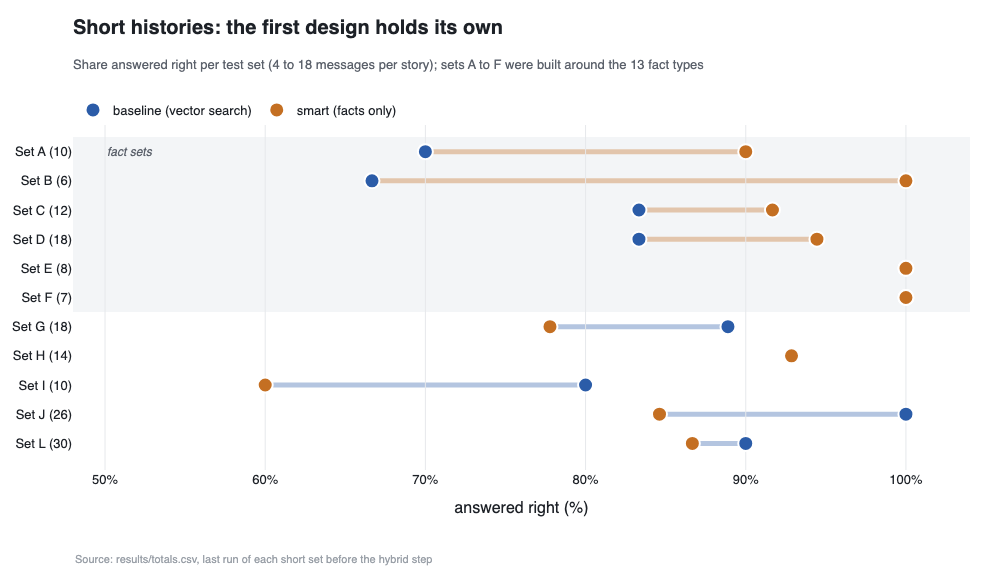

In [2]:
ch.short_sets()

### Key insights

- **On the fact sets A to F** (built around the 13 fact types) smart answers as well as vector search or better, with about half the prompt and no outdated values.
- **On sets G to L** (episodes, plans, fresh data) the raw messages already do better: some of what users say does not fit a fact.


Every change to the design was checked again on the earlier sets.  
The map shows the gap between the two modes on each set across those regression runs.


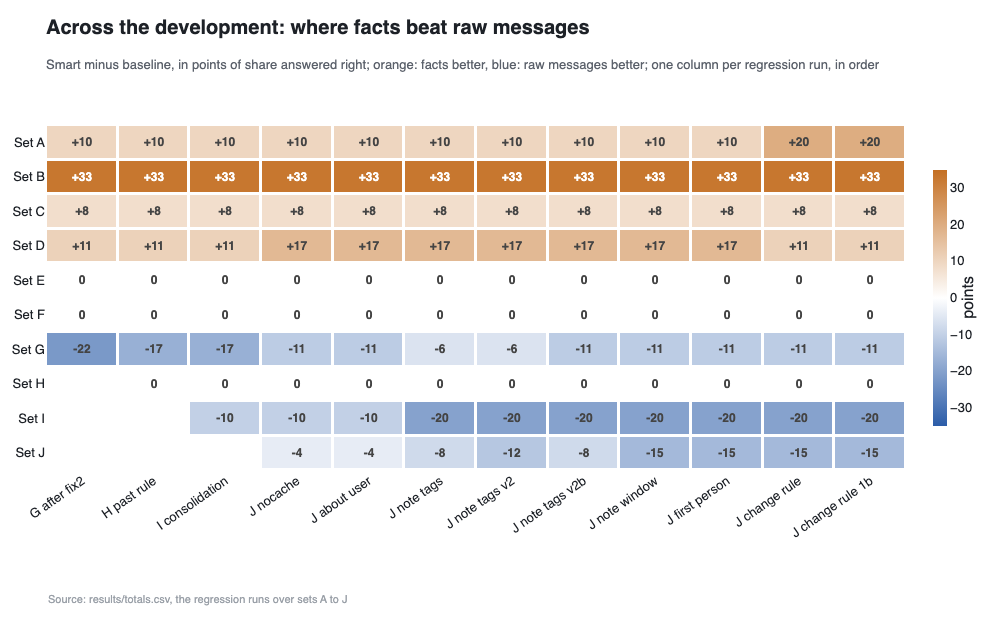

In [3]:
ch.development_map()

### Key insights

- **The split held through the whole development:** facts led on sets A to D in every run, and trailed on G, I and J in every run.
- **Fixes moved the weak sets little:** the gap on G narrowed from -22 to -11, while I and J widened as rules were added for other cases.

---


## The setback on long histories

Set M was the first test on long histories: three users with 92 to 100 messages over about 18 months, written before its run.


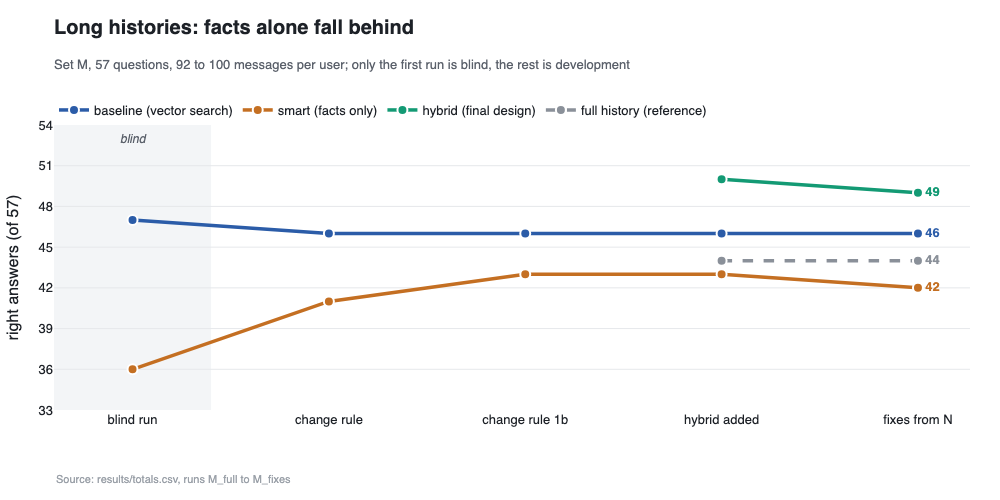

In [4]:
ch.set_m()

### Key insights

- **Facts alone lost clearly on the blind run** (36 against 47). Every message is a new chance for an 8B model to store a fact wrongly (a friend's city as the user's, a house viewing as a move), and over 18 months the errors add up. The raw sentences were more reliable than the facts taken from them.
- **Rules for when a value really changed** narrowed the gap (36 to 43) but did not close it.
- **Hybrid**, which keeps the messages and adds facts on top, passed the baseline. These later runs are development on a set already seen, so they motivate the design; they do not prove it.

---


## The result on blind tests

Hybrid uses facts as annotations on the conversation:

- a message whose fact is outdated is marked: `[outdated: Lives in: Oslo -> now Kristiansand]`;
- a question about the past gets a timeline: `Lives in, oldest first: Stavanger -> Oslo -> Kristiansand (now)`;
- current facts, allergies included, go on top.

It was tested on two new sets, N and O, each written before the version it tests and run once.


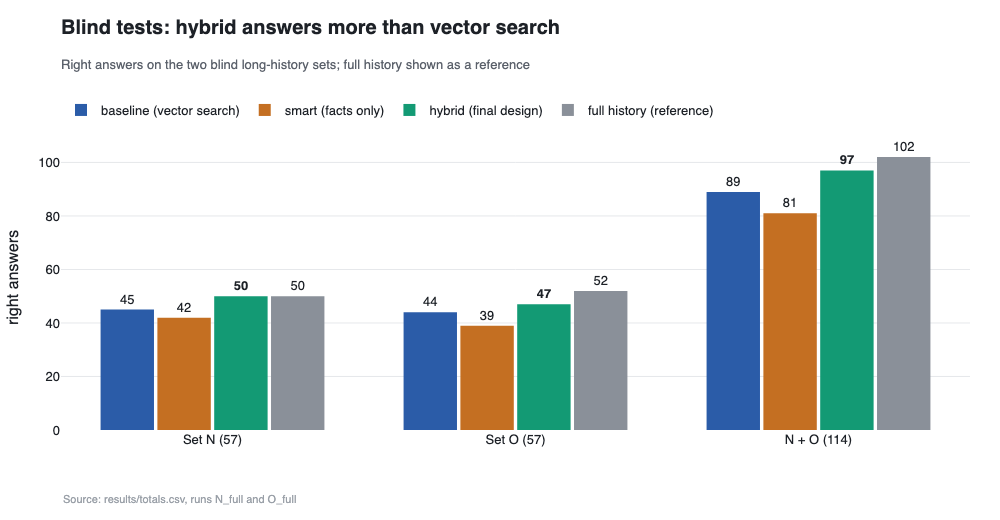

In [5]:
ch.headline()

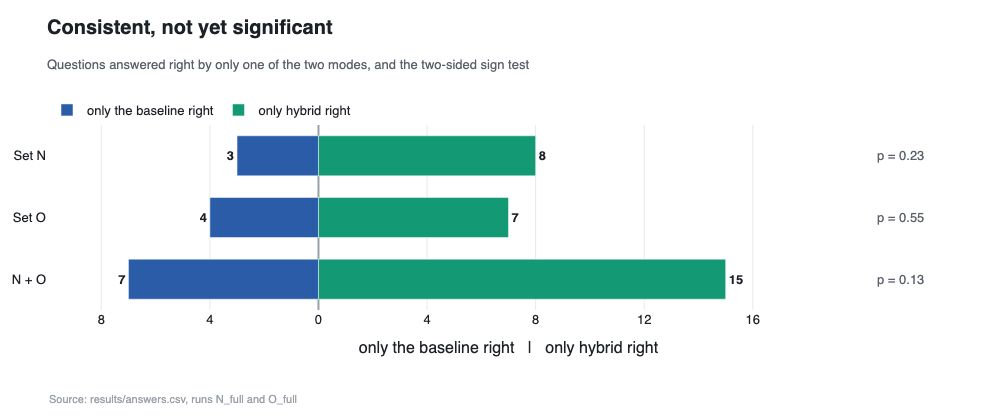

In [ ]:
ch.significance()

**p:** the chance of a split at least this uneven if both modes were equally good, from the sign test (each question answered right by only one mode counted as a coin flip).  
Below 0.05 is the usual bar for a real difference; at 0.13, a 15-to-7 split would still happen about 1 time in 8 by luck.

### Key insights

- **Hybrid beat vector search on both blind sets**: +5 on N and +3 on O, each meeting the threshold of +3 fixed before the run; 97 against 89 out of 114 overall.
- **Consistent, but not proven:** on the questions where only one of the two was right, hybrid won 15 to 7, which a sign test puts at p = 0.13.
- **Facts alone stayed behind** vector search on both sets.

---


## Where the facts help, and where they hurt


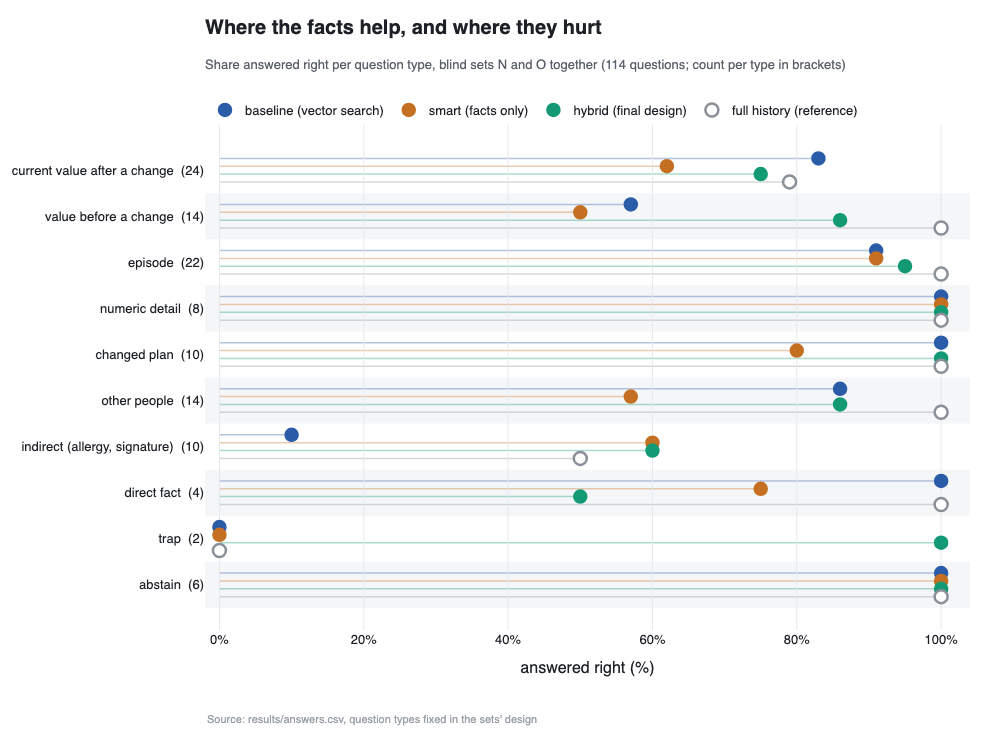

In [7]:
ch.by_type()

### Key insights

- **Gains come from the annotations:** questions about the past (86% against 57%, from the timeline) and indirect questions (60% against 10%, from the allergy lines).
- **Losses come from wrong facts:** on current values after a change hybrid is below vector search (75% against 83%), because a stale fact on top outweighed the right message below it. Every hybrid loss on the blind sets traces back to a fact that was wrong, stale or filtered out.
- **Small rows are anecdotes:** 2 trap and 4 direct questions.

---


## The cost, and the open question


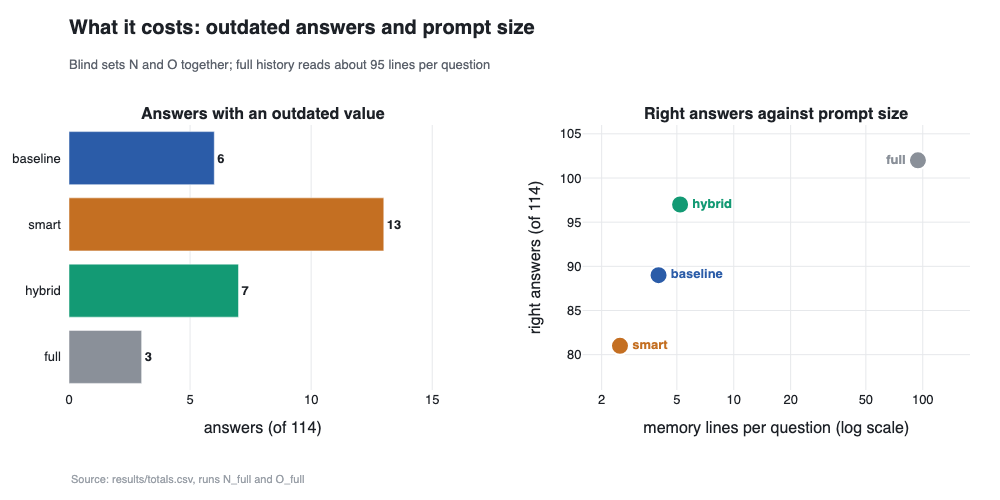

In [8]:
ch.cost()

### Key insights

- **The whole history scored best** (102 of 114) with the fewest outdated answers, at about 20 times hybrid's prompt.
- **These histories fit the model whole** (about 1,100 tokens per user). A memory system has to earn its place on histories longer than the context window, or on prompt cost; these sets do not reach that length.


---

# Conclusions

- **Facts work best as annotations on the conversation, not as its replacement.** Replacing messages with extracted facts lost to vector search on every long set; keeping the messages and adding facts beat it on both blind sets, though not significantly.
- **Extraction is the bottleneck.** The small model's wrong or missing facts explain the first design's losses and all of hybrid's.
- **Next:** histories longer than the context window, and a stronger extraction model.

## Appendix

Every blind run of the project, in the order the sets were written.


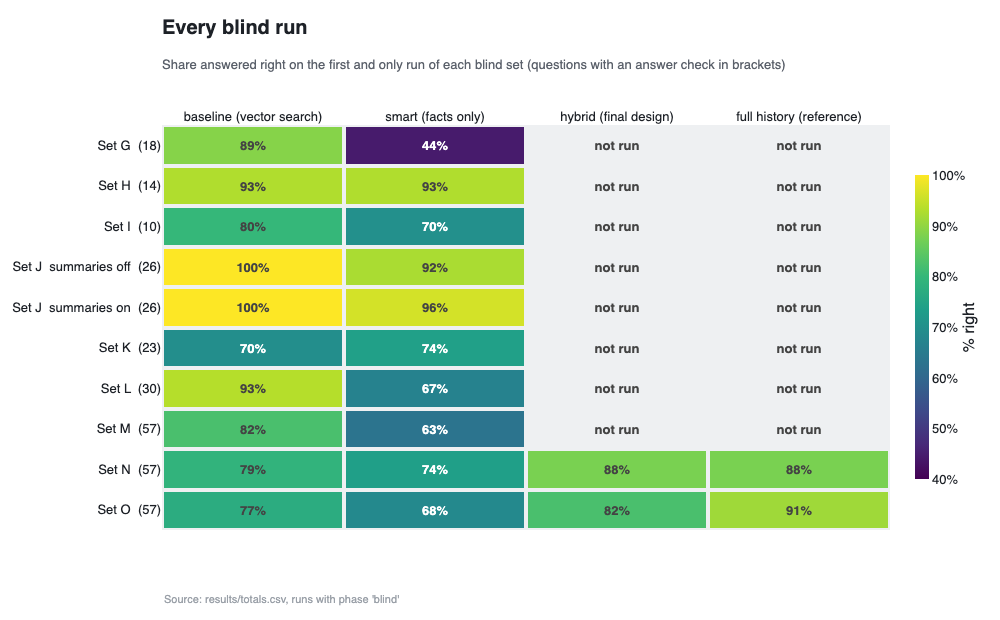

In [9]:
ch.blind_runs()